# 01. Color Quantization

목표는 원본 이미지를 사람이 색칠하기 쉬운 제한된 색상 수로 단순화하는 것입니다.

비교 알고리즘:

- K-Means Clustering: 이미지 픽셀을 K개의 대표 색상 군집으로 묶습니다.
- Posterization: RGB 채널을 균등 구간으로 나누는 빠른 단순화 방식입니다.
- Median Cut: 색상 분포가 넓은 축을 반복 분할해 대표 팔레트를 만듭니다.

최종 기본 알고리즘은 색상 유지 품질과 발표 설명 용이성을 고려해 K-Means로 선택합니다.

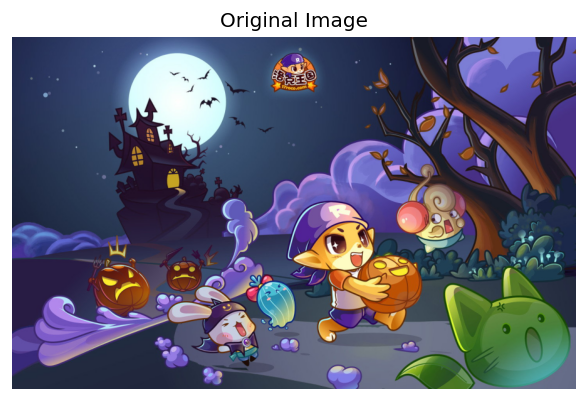

In [1]:
import os
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np

# 공통 함수가 들어 있는 src 폴더를 import 경로에 추가합니다.
sys.path.append("src")
from coloringbook_utils import *

# 결과 저장 폴더(outputs)와 샘플 입력 폴더(data)를 생성합니다.
ensure_dirs()
plt.rcParams["figure.dpi"] = 120

# 직접 사용할 이미지가 있으면 여기에 경로를 넣으세요.
# 예: IMAGE_PATH = "data/ych.jpg"
IMAGE_PATH = "data/ych.jpg"

# IMAGE_PATH가 None이면 발표/실험용 샘플 이미지가 자동 생성됩니다.
image = load_image(IMAGE_PATH)
show_images([("Original Image", image)], cols=1, figsize=(5, 5))

## K-Means, Posterization, Median Cut 실행

아래 셀에서 원하는 색상 개수 `K`를 바꿀 수 있습니다.

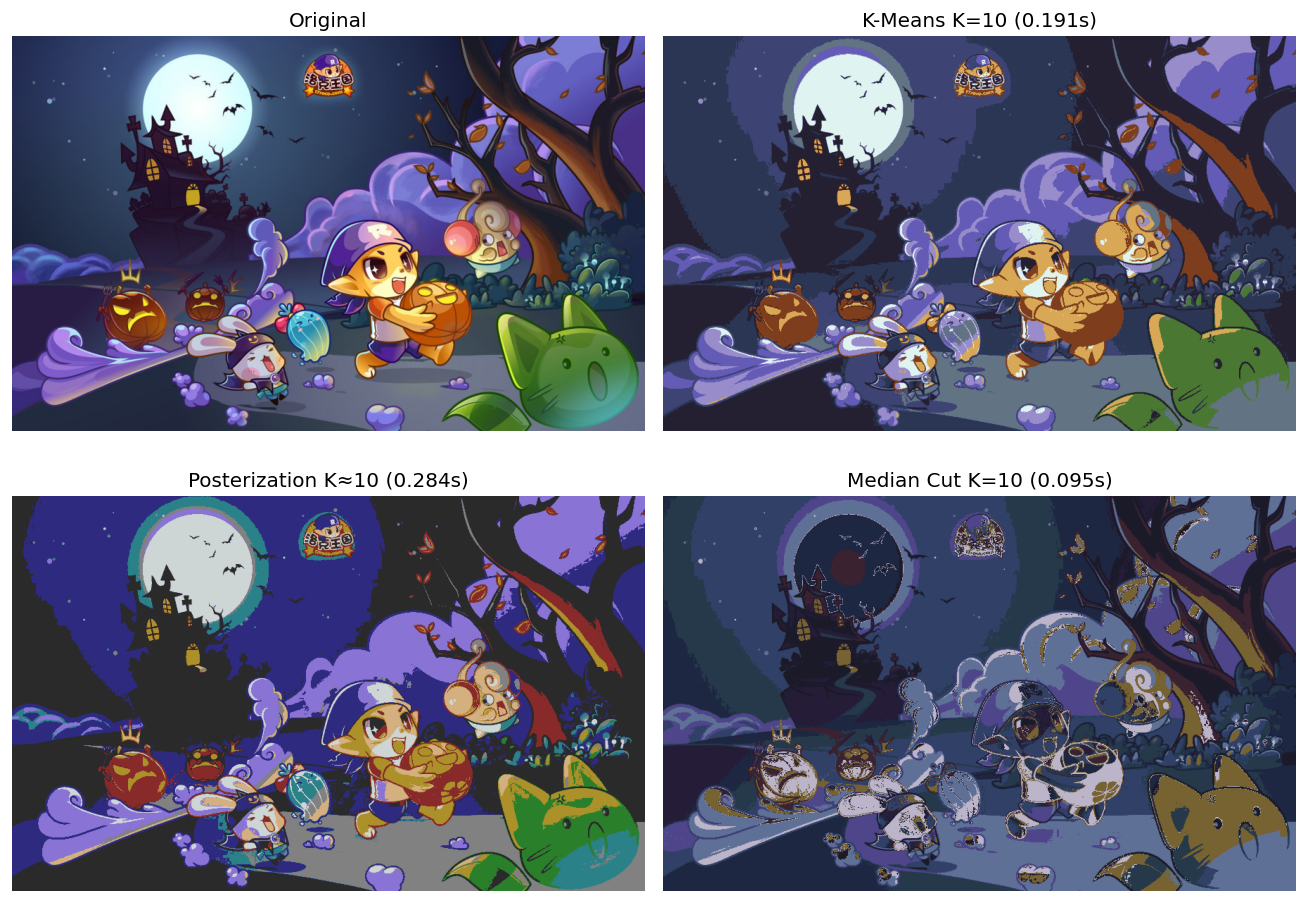

In [2]:
# K는 최종 팔레트에 남길 대표 색상 개수입니다.
# K가 작으면 색칠은 쉬워지고, K가 크면 원본 색상 보존이 좋아집니다.
K = 10

# K-Means: 픽셀을 K개 군집으로 묶고 각 군집 중심색으로 이미지를 치환합니다.
(kmeans_img, kmeans_palette), kmeans_time = timed_call(kmeans_quantization, image, K)

# Posterization: RGB 채널을 일정한 구간으로 나눠 빠르게 색상을 줄입니다.
(poster_img, poster_palette), poster_time = timed_call(posterization, image, K)

# Median Cut: 색상 분포가 넓은 축을 반복 분할해 대표 색상표를 만듭니다.
(median_img, median_palette), median_time = timed_call(median_cut_quantization, image, K)

# 각 알고리즘 결과를 파일로 저장해 보고서/발표 자료에 바로 사용할 수 있게 합니다.
save_image_rgb("flowersoutput/01_kmeans.png", kmeans_img)
save_image_rgb("flowersoutput/01_posterization.png", poster_img)
save_image_rgb("flowersoutput/01_median_cut.png", median_img)

show_images([
    ("Original", image),
    (f"K-Means K={K} ({kmeans_time:.3f}s)", kmeans_img),
    (f"Posterization K≈{K} ({poster_time:.3f}s)", poster_img),
    (f"Median Cut K={K} ({median_time:.3f}s)", median_img),
], cols=2, figsize=(11, 8), save_path="flowersoutput/01_quantization_compare.png")

## RGB 색상표

색상표는 최종 컬러링북 번호와 연결되는 색상 안내표로 사용할 수 있습니다.

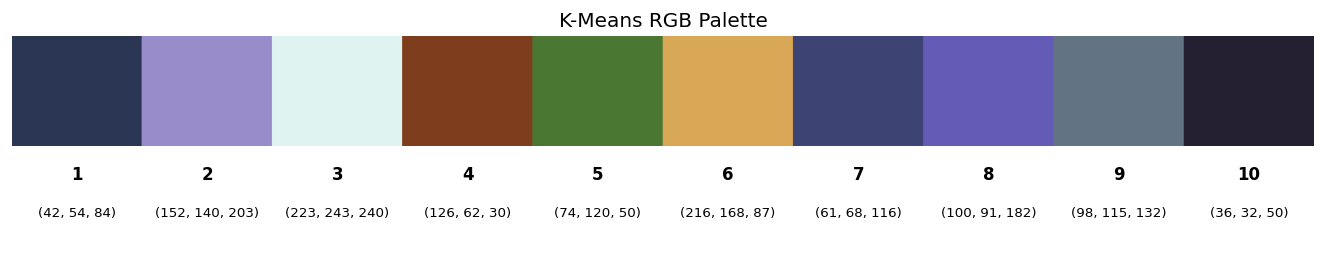

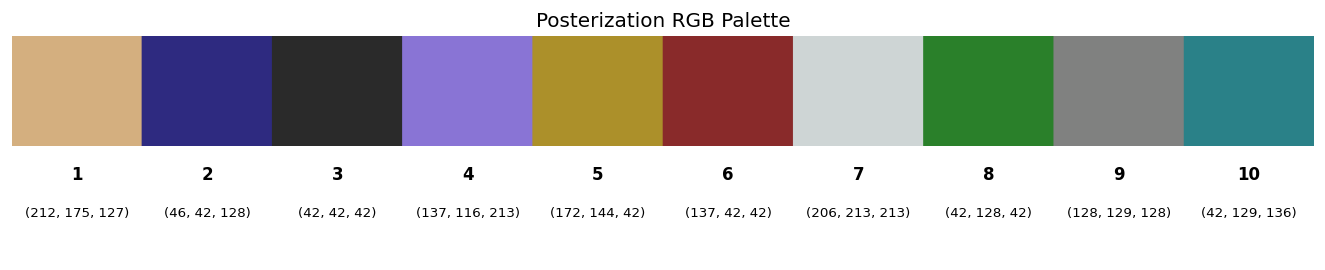

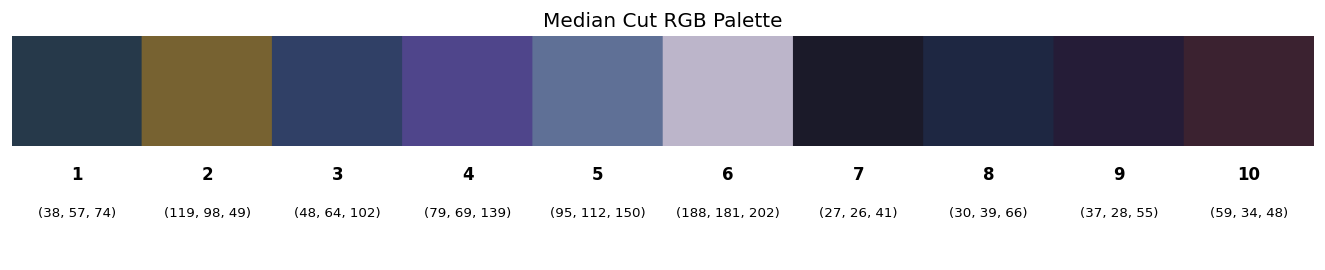

In [3]:
plot_palette(kmeans_palette, "K-Means RGB Palette", "flowersoutput/01_kmeans_palette.png")
plot_palette(poster_palette, "Posterization RGB Palette", "flowersoutput/01_poster_palette.png")
plot_palette(median_palette, "Median Cut RGB Palette", "flowersoutput/01_median_palette.png")

## 알고리즘 정량 비교

세 알고리즘을 같은 K로 비교합니다. 지금까지는 실행 시간만 봤지만, "원본 색을 얼마나 잘 보존했는가"를 함께 측정해야 K-Means 채택을 정량적으로 뒷받침할 수 있습니다.

- `runtime_sec`: 실행 시간, 낮을수록 빠름
- `color_error`: 원본과 양자화 이미지의 Lab 색 거리 평균, 낮을수록 원본 색 보존 우수
- `unique_colors`: 요청한 K 대비 실제로 남은 색 개수

주의: `data/sample_input.png` 같은 합성 이미지는 원래 색이 거의 없어 색 오차 차이가 잘 드러나지 않습니다. 실제 사진으로 위쪽의 `IMAGE_PATH`를 바꿔서 측정해야 의미 있는 비교가 나옵니다.

In [4]:
# 세 알고리즘을 같은 K 기준으로 정량 비교합니다.
# kmeans_img / poster_img / median_img 는 위 "K-Means, Posterization, Median Cut 실행" 셀에서 만들어집니다.
quality_rows = []
for name, result, runtime in [
    ("K-Means", kmeans_img, kmeans_time),
    ("Posterization", poster_img, poster_time),
    ("Median Cut", median_img, median_time),
]:
    quality_rows.append({
        "algorithm": name,
        "runtime_sec": runtime,
        # quantization_error: 원본과 양자화 이미지의 Lab 색 거리 평균 (낮을수록 원본 보존 우수)
        "color_error": quantization_error(image, result),
        # count_unique_colors: 실제로 남은 색 개수 (요청 K가 상한일 뿐 실제는 다를 수 있음)
        "unique_colors": count_unique_colors(result),
    })

print(f"입력 이미지: {IMAGE_PATH}  (원본 색 수: {count_unique_colors(image)})")
print(f"요청 K = {K}\n")
print_table(quality_rows, columns=["algorithm", "runtime_sec", "color_error", "unique_colors"])

입력 이미지: data/ych.jpg  (원본 색 수: 175886)
요청 K = 10

algorithm     | runtime_sec | color_error | unique_colors
--------------+-------------+-------------+--------------
K-Means       | 0.1909      | 16.5292     | 10           
Posterization | 0.2844      | 28.3053     | 10           
Median Cut    | 0.0954      | 32.7936     | 10           


## 5색, 10색, 20색, 50색 비교

색상 개수가 늘어나면 원본 보존력은 좋아지지만, 색칠해야 할 영역과 인지 복잡도도 함께 증가합니다.

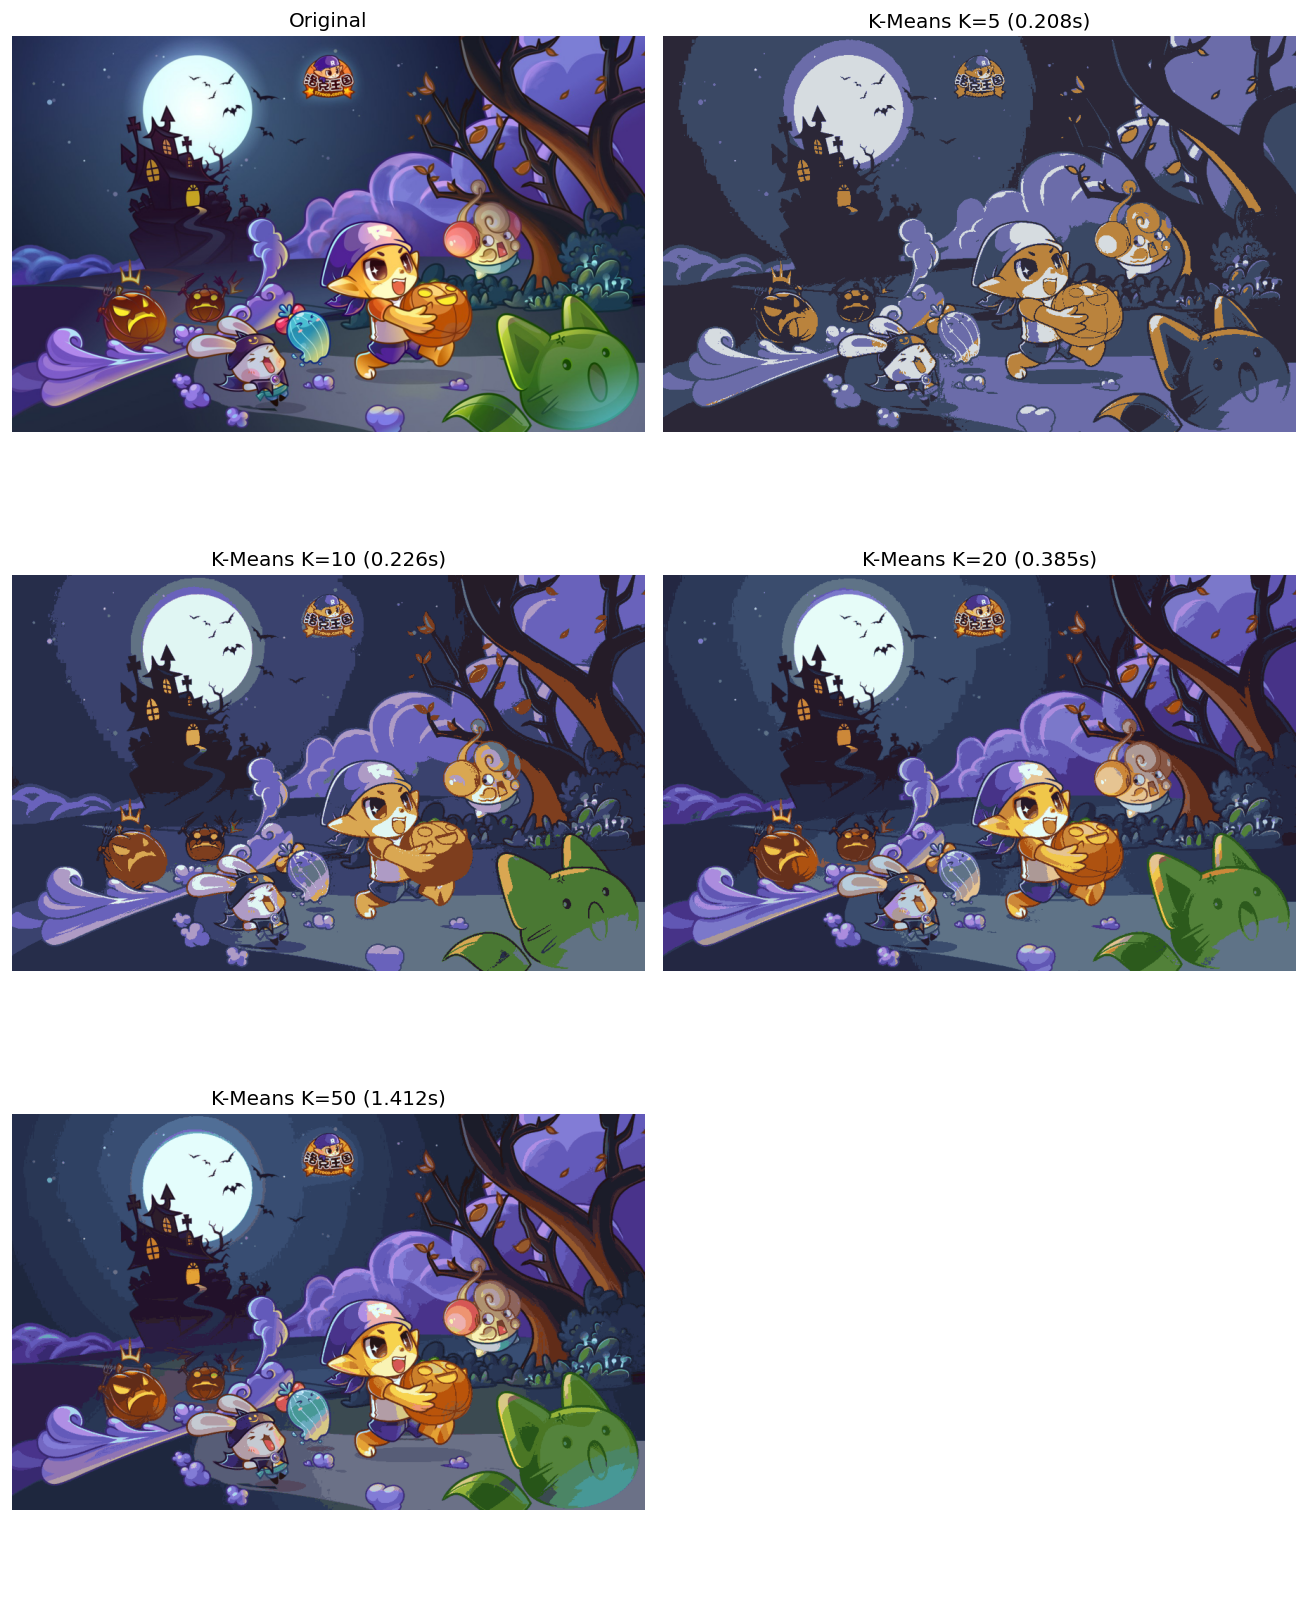

algorithm | K  | runtime_sec | palette_size
----------+----+-------------+-------------
K-Means   | 5  | 0.2078      | 5           
K-Means   | 10 | 0.2264      | 10          
K-Means   | 20 | 0.3853      | 20          
K-Means   | 50 | 1.4121      | 50          


In [5]:
# 색상 수가 늘어날 때 시각 품질과 복잡도가 어떻게 변하는지 비교합니다.
k_values = [5, 10, 20, 50]
comparison_items = [("Original", image)]
timing_rows = []

for k in k_values:
    # 같은 입력 이미지에 대해 K만 바꿔 K-Means를 반복 실행합니다.
    (result, palette), runtime = timed_call(kmeans_quantization, image, k)
    save_image_rgb(f"flowersoutput/01_kmeans_k{k}.png", result)
    comparison_items.append((f"K-Means K={k} ({runtime:.3f}s)", result))
    timing_rows.append({"algorithm": "K-Means", "K": k, "runtime_sec": runtime, "palette_size": len(palette)})

show_images(comparison_items, cols=2, figsize=(11, 14), save_path="flowersoutput/01_k_compare.png")
print_table(timing_rows)

## 이미지별 최소 표현 색 개수 추정 개선

고정된 K 하한선을 정하는 대신, 현재 입력 이미지가 어느 정도 알아볼 수 있게 표현되는 최소 색상 수를 추정합니다.

기존 방식은 원본 이미지를 그대로 `K=2~30`까지 전부 K-Means로 탐색했기 때문에, 그림자/질감 같은 작은 색 변화까지 반영되어 K가 커지고 실행 시간도 길어질 수 있습니다.

개선 방식은 다음 세 가지를 적용합니다.

- `smoothing`: K 추정 전에 Bilateral Filter로 그림자와 질감을 완화합니다.
- `fast search`: 모든 K를 보지 않고 대표 후보 K를 먼저 확인합니다.
- `difficulty`: 추천 최소 K를 기준으로 쉬움/보통/어려움 색상 수를 제안합니다.


입력 이미지: data/ych.jpg
원본 기준 추천 최소 K: 16 / 탐색 시간: 0.261s
Smoothing + 빠른 탐색 추천 최소 K: 20 / 탐색 시간: 0.146s
탐색 속도 개선 배율: 1.79x
원본 색 다양성(Lab spread): 50.5400
Smoothing 후 색 다양성(Lab spread): 48.5656
보존율 기준: 75%

[기존 방식] 원본 기준 K=2~30 탐색
K  | runtime_sec | color_error | retention | palette_size
---+-------------+-------------+-----------+-------------
2  | 0.0089      | 36.8806     | 0.2703    | 2           
3  | 0.0068      | 31.2369     | 0.3819    | 3           
4  | 0.0133      | 26.9896     | 0.4660    | 4           
5  | 0.0117      | 23.8446     | 0.5282    | 5           
6  | 0.0160      | 22.2071     | 0.5606    | 6           
7  | 0.0090      | 20.6435     | 0.5915    | 7           
8  | 0.0094      | 20.1810     | 0.6007    | 8           
9  | 0.0219      | 18.3316     | 0.6373    | 9           
10 | 0.0247      | 16.8138     | 0.6673    | 10          
11 | 0.0260      | 15.8441     | 0.6865    | 11          
12 | 0.0258      | 14.9567     | 0.7041    | 12          
13 | 0.0196      | 1

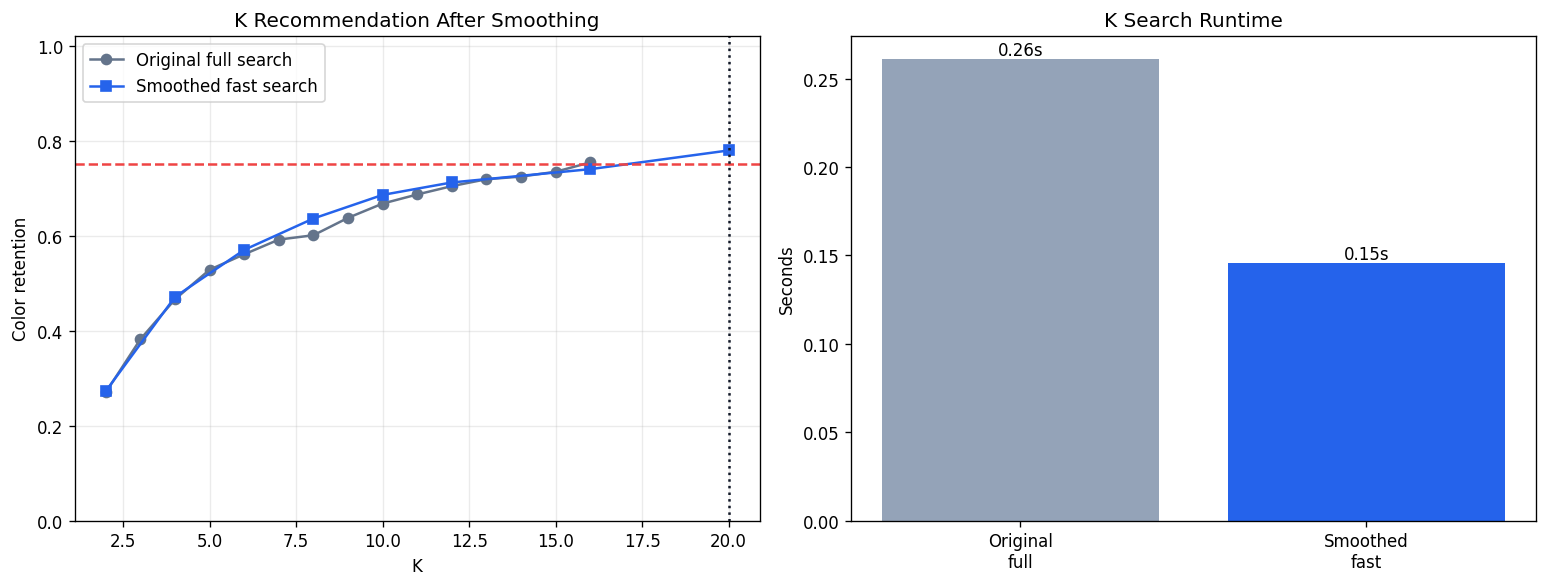

/Users/gyeongseopkim/HCI_project/HCI_PROJECT/server/src/coloringbook_utils.py:100: UserWarning: Glyph 49772 (\N{HANGUL SYLLABLE SWI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/gyeongseopkim/HCI_project/HCI_PROJECT/server/src/coloringbook_utils.py:100: UserWarning: Glyph 50880 (\N{HANGUL SYLLABLE UM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/gyeongseopkim/HCI_project/HCI_PROJECT/server/src/coloringbook_utils.py:100: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/gyeongseopkim/HCI_project/HCI_PROJECT/server/src/coloringbook_utils.py:100: UserWarning: Glyph 53685 (\N{HANGUL SYLLABLE TONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/gyeongseopkim/HCI_project/HCI_PROJECT/server/src/coloringbook_utils.py:100: UserWarning: Glyph 50612 (\N{HANGUL SYLLABLE EO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/gyeongseopkim/HCI_project/HCI_PROJECT/server/src/c

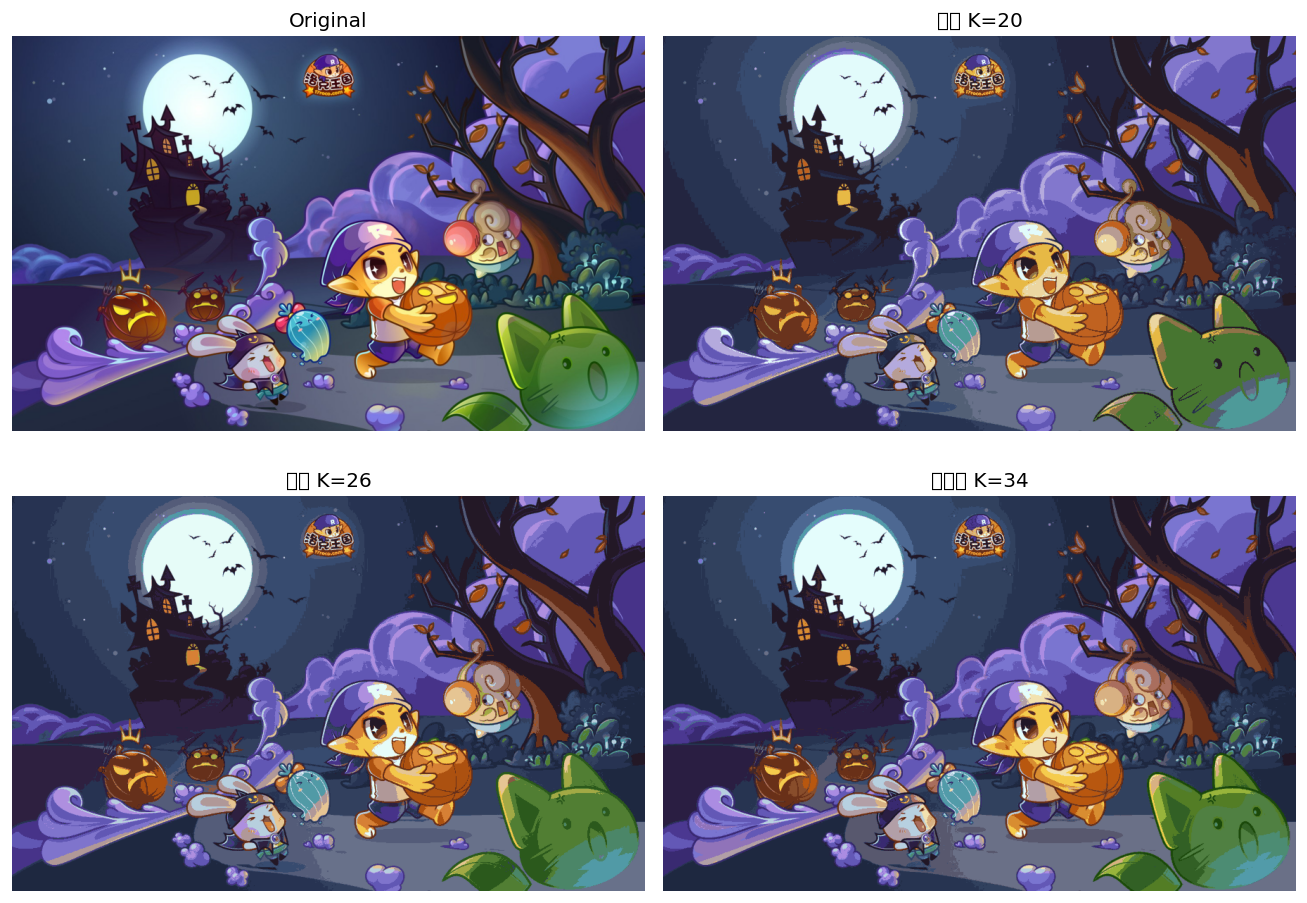

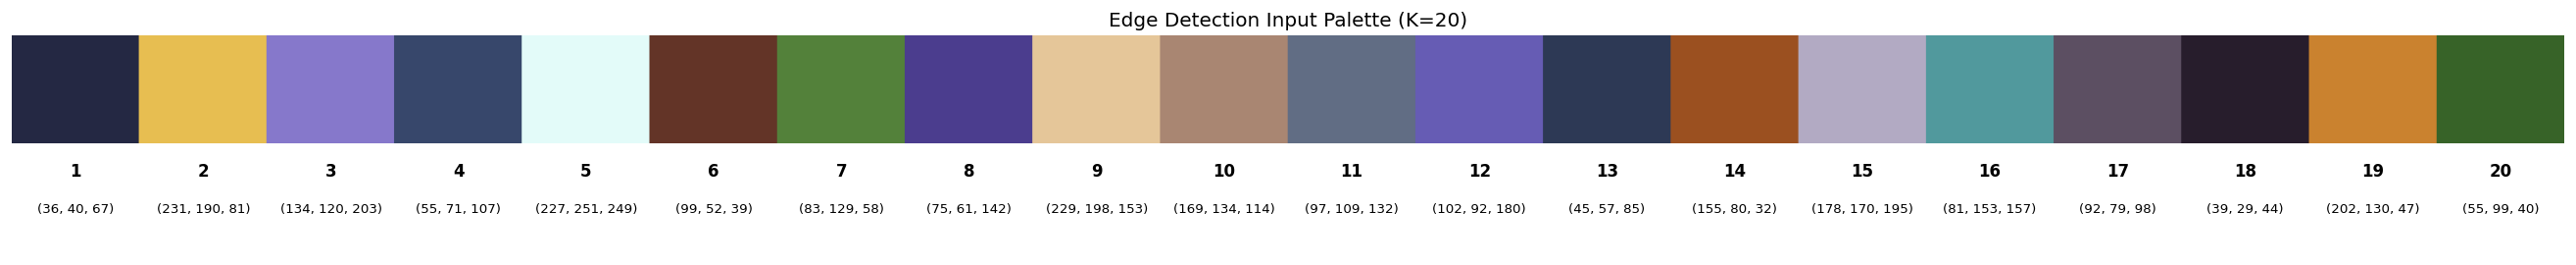

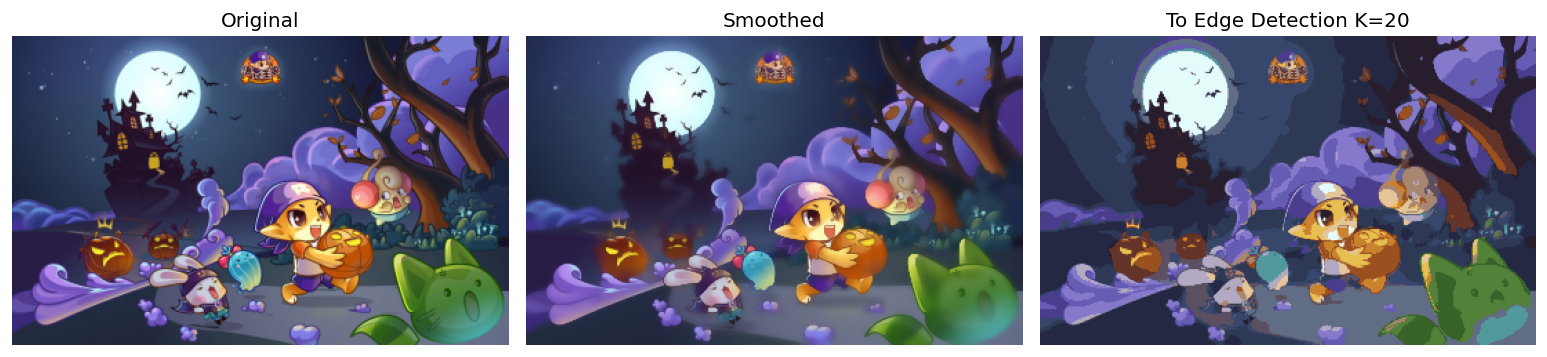

02번 Edge Detection 입력 이미지 저장: flowersoutput/01_to_02_edge_input.png (K=20)


In [6]:
# 현재 입력 이미지에서 표현 가능한 최소 색 개수를 더 빠르고 안정적으로 추정합니다.
# 원본 기준과 smoothing 기준을 비교해, 그림자/질감 완화가 K 추천에 미치는 영향을 확인합니다.

def lab_color_spread(image):
    """원본 이미지 자체의 색 다양성 크기. 값이 클수록 색 변화가 많은 이미지입니다."""
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB).astype(np.float32)
    mean_lab = lab.reshape(-1, 3).mean(axis=0)
    return float(np.mean(np.linalg.norm(lab - mean_lab, axis=2)))

def resize_for_k_search(image, max_size=360):
    """K 추천용으로만 이미지를 축소해 반복 K-Means 시간을 줄입니다."""
    h, w = image.shape[:2]
    scale = min(1.0, max_size / max(h, w))
    if scale >= 1.0:
        return image
    return cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)

def smooth_for_k_search(image):
    """그림자와 질감으로 인한 과도한 색 분리를 줄이는 K 추천용 평탄화입니다."""
    return cv2.bilateralFilter(image, d=9, sigmaColor=90, sigmaSpace=90)

def estimate_min_k(image, candidate_ks, retention_threshold=0.75, attempts=1):
    """후보 K를 순서대로 보며 색 보존율 기준을 처음 만족하는 K를 찾습니다."""
    spread = max(lab_color_spread(image), 1e-6)
    rows = []
    recommended_k = None
    for candidate_k in candidate_ks:
        (candidate_img, candidate_palette), runtime = timed_call(
            kmeans_quantization, image, candidate_k, attempts
        )
        error = quantization_error(image, candidate_img)
        retention = max(0.0, 1.0 - error / spread)
        rows.append({
            "K": candidate_k,
            "runtime_sec": runtime,
            "color_error": error,
            "retention": retention,
            "palette_size": len(candidate_palette),
        })
        if retention >= retention_threshold and recommended_k is None:
            recommended_k = candidate_k
            break
    if recommended_k is None:
        recommended_k = candidate_ks[-1]
    return recommended_k, rows, spread

def difficulty_k_options(min_k, max_k=50):
    """추천 최소 K를 바탕으로 UI에 제시할 난이도별 색상 수를 만듭니다."""
    easy = int(np.clip(min_k, 2, max_k))
    normal = int(np.clip(min_k + 6, 2, max_k))
    hard = int(np.clip(min_k + 14, 2, max_k))
    return [
        {"difficulty": "쉬움", "level": "easy", "K": easy, "description": "색 수를 최소화해 칠하기 쉬운 도안"},
        {"difficulty": "보통", "level": "normal", "K": normal, "description": "색 표현과 색칠 부담의 균형"},
        {"difficulty": "어려움", "level": "hard", "K": hard, "description": "원본 색감을 더 살리는 세밀한 도안"},
    ]

RETENTION_THRESHOLD = 0.75
FULL_K_CANDIDATES = list(range(2, 31))
FAST_K_CANDIDATES = [2, 4, 6, 8, 10, 12, 16, 20, 24, 30]

search_image_original = resize_for_k_search(image)
search_image_smooth = smooth_for_k_search(search_image_original)

# 비교 기준: 기존 방식처럼 K=2~30 전체를 원본 기준으로 탐색합니다.
original_min_k, original_rows, original_spread = estimate_min_k(
    search_image_original, FULL_K_CANDIDATES, RETENTION_THRESHOLD, attempts=1
)

# 개선 방식: smoothing 후 대표 후보 K만 탐색하고 기준 만족 시 조기 종료합니다.
smooth_min_k, smooth_rows, smooth_spread = estimate_min_k(
    search_image_smooth, FAST_K_CANDIDATES, RETENTION_THRESHOLD, attempts=1
)
difficulty_rows = difficulty_k_options(smooth_min_k)

original_runtime = sum(row["runtime_sec"] for row in original_rows)
smooth_runtime = sum(row["runtime_sec"] for row in smooth_rows)
speedup = original_runtime / max(smooth_runtime, 1e-6)

print(f"입력 이미지: {IMAGE_PATH}")
print(f"원본 기준 추천 최소 K: {original_min_k} / 탐색 시간: {original_runtime:.3f}s")
print(f"Smoothing + 빠른 탐색 추천 최소 K: {smooth_min_k} / 탐색 시간: {smooth_runtime:.3f}s")
print(f"탐색 속도 개선 배율: {speedup:.2f}x")
print(f"원본 색 다양성(Lab spread): {original_spread:.4f}")
print(f"Smoothing 후 색 다양성(Lab spread): {smooth_spread:.4f}")
print(f"보존율 기준: {RETENTION_THRESHOLD:.0%}\n")

print("[기존 방식] 원본 기준 K=2~30 탐색")
print_table(original_rows, columns=["K", "runtime_sec", "color_error", "retention", "palette_size"])
print("\n[개선 방식] Smoothing 후 빠른 후보 K 탐색")
print_table(smooth_rows, columns=["K", "runtime_sec", "color_error", "retention", "palette_size"])
print("\n[난이도별 추천 K]")
print_table(difficulty_rows, columns=["difficulty", "K", "description"])

# 그래프 1: 원본 기준 전체 탐색과 smoothing 후 빠른 탐색의 보존율/시간 비교
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    [row["K"] for row in original_rows],
    [row["retention"] for row in original_rows],
    marker="o",
    label="Original full search",
    color="#64748b",
)
axes[0].plot(
    [row["K"] for row in smooth_rows],
    [row["retention"] for row in smooth_rows],
    marker="s",
    label="Smoothed fast search",
    color="#2563eb",
)
axes[0].axhline(RETENTION_THRESHOLD, color="#ef4444", linestyle="--", linewidth=1.5)
axes[0].axvline(smooth_min_k, color="#111827", linestyle=":", linewidth=1.5)
axes[0].set_title("K Recommendation After Smoothing")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Color retention")
axes[0].set_ylim(0, 1.02)
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].bar(["Original\nfull", "Smoothed\nfast"], [original_runtime, smooth_runtime], color=["#94a3b8", "#2563eb"])
axes[1].set_title("K Search Runtime")
axes[1].set_ylabel("Seconds")
for i, value in enumerate([original_runtime, smooth_runtime]):
    axes[1].text(i, value, f"{value:.2f}s", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("flowersoutput/01_k_recommendation_smoothing_fast.png", dpi=160, bbox_inches="tight")
plt.show()

# 그래프 2: 난이도별 K로 만든 실제 색상 단순화 결과
difficulty_items = [("Original", image)]
for row in difficulty_rows:
    diff_img, _ = kmeans_quantization(image, row["K"], attempts=1)
    save_image_rgb(f"flowersoutput/01_difficulty_{row['level']}_k{row['K']}.png", diff_img)
    difficulty_items.append((f"{row['difficulty']} K={row['K']}", diff_img))

show_images(
    difficulty_items,
    cols=2,
    figsize=(11, 8),
    save_path="flowersoutput/01_difficulty_k_options.png",
)

# 02 Edge Detection으로 넘길 입력 이미지입니다.
# 원본을 그대로 넘기면 질감/그림자 노이즈까지 edge로 잡힐 수 있으므로,
# smoothing 후 추천 최소 K로 단순화한 이미지를 명시적으로 저장합니다.
edge_input_img, edge_input_palette = kmeans_quantization(search_image_smooth, smooth_min_k, attempts=1)
save_image_rgb("flowersoutput/01_to_02_edge_input.png", edge_input_img)
plot_palette(
    edge_input_palette,
    f"Edge Detection Input Palette (K={smooth_min_k})",
    "flowersoutput/01_to_02_edge_input_palette.png",
)

show_images(
    [
        ("Original", search_image_original),
        ("Smoothed", search_image_smooth),
        (f"To Edge Detection K={smooth_min_k}", edge_input_img),
    ],
    cols=3,
    figsize=(13, 4),
    save_path="flowersoutput/01_to_02_edge_input_compare.png",
)
print(f"02번 Edge Detection 입력 이미지 저장: flowersoutput/01_to_02_edge_input.png (K={smooth_min_k})")


## 비교 분석

위 정량 비교(단일 이미지 + 다중 이미지), K값 비교, 최소 표현 K 추정 결과를 종합하면 다음과 같습니다.

- 색상 유지 품질: K-Means는 4개 이미지 모두에서 색 오차(Lab 거리)가 가장 낮았습니다. 실제 색 분포에 맞춰 대표색을 찾기 때문에 이미지 종류와 무관하게 원본을 가장 잘 보존합니다. 이것이 K-Means를 최종 알고리즘으로 채택한 핵심 근거입니다.
- Posterization: 색 공간을 균등 구간으로 기계적으로 나누기 때문에 모든 이미지에서 색 오차가 일관되게 큽니다(약 20~30). 특히 그라데이션 영역에서 계단 현상(밴딩)이 두드러집니다.
- Median Cut: 빠르지만 불안정합니다. 마네 그림처럼 잘 맞는 경우도 있으나, 노을 풍경에서는 색 오차가 약 126으로 급증해 결과가 시각적으로 무너졌습니다. 단순한 분할 기준 때문에 색 분포에 따라 품질 편차가 큽니다.
- 최소 표현 K: 고정된 하한선을 임의로 정하지 않고, 현재 이미지에서 색 보존율이 기준을 처음 만족하는 최소 K를 추정합니다. 단순한 이미지는 낮은 K로도 표현 가능하고, 색 변화가 많은 이미지는 더 큰 K가 필요합니다.
- 사용자 관점: K가 작을수록 색칠은 쉽지만 원본 정보가 손실되고, K가 커지면(예: K=50) 색 정밀도는 올라가지만 처리 시간과 색칠 복잡도가 급증합니다. 따라서 추천 최소 K를 기준으로 사용자가 난이도에 맞게 K를 조절하도록 하는 것이 적절합니다.

## 다중 이미지 정량 비교

알고리즘을 사진 한 장으로만 평가하면 "그 사진에서 우연히 좋았다"는 반박이 가능합니다. 성격이 다른 4장(마네 그림 / 인물 / 꽃 정원 / 노을 풍경)에 세 알고리즘을 모두 돌려, 결과가 이미지 종류와 무관하게 일관적인지 확인합니다.

- `runtime_sec`: 알고리즘별 실행 시간 (RUNS회 평균)
- `color_error`: 원본 대비 Lab 색 거리 평균, 낮을수록 원본 보존 우수
- `unique_colors`: 실제로 남은 색 개수

In [7]:
# 02번 Edge Detection 입력 이미지 기준 x 3개 알고리즘 정량 비교
# 각 알고리즘을 RUNS회 실행해 런타임 평균을 내고, 색 오차와 실제 색 수를 측정합니다.
COMPARE_IMAGES = {
    "YCH Input": "data/ych.jpg",
}
COMPARE_K = 10
RUNS = 3  # 런타임 측정 반복 횟수 (평균)

ALGORITHMS = {
    "K-Means":       kmeans_quantization,
    "Posterization": posterization,
    "Median Cut":    median_cut_quantization,
}

multi_rows = []
multi_results = {}  # (이미지명, 알고리즘명) -> 결과 이미지
for img_name, img_path in COMPARE_IMAGES.items():
    img = load_image(img_path)
    multi_results[(img_name, "Original")] = img
    for algo_name, algo_fn in ALGORITHMS.items():
        # 런타임은 RUNS회 평균, 결과 이미지는 마지막 실행분을 사용
        times = []
        for _ in range(RUNS):
            (result, _palette), rt = timed_call(algo_fn, img, COMPARE_K)
            times.append(rt)
        multi_results[(img_name, algo_name)] = result
        multi_rows.append({
            "image": img_name,
            "algorithm": algo_name,
            "runtime_sec": sum(times) / len(times),
            "color_error": quantization_error(img, result),
            "unique_colors": count_unique_colors(result),
        })

print(f"K = {COMPARE_K}, runtime = {RUNS}회 평균")
print()
print_table(multi_rows, columns=["image", "algorithm", "runtime_sec", "color_error", "unique_colors"])

K = 10, runtime = 3회 평균

image     | algorithm     | runtime_sec | color_error | unique_colors
----------+---------------+-------------+-------------+--------------
YCH Input | K-Means       | 0.2297      | 16.4016     | 10           
YCH Input | Posterization | 0.3098      | 29.2482     | 10           
YCH Input | Median Cut    | 0.0789      | 32.7936     | 10           


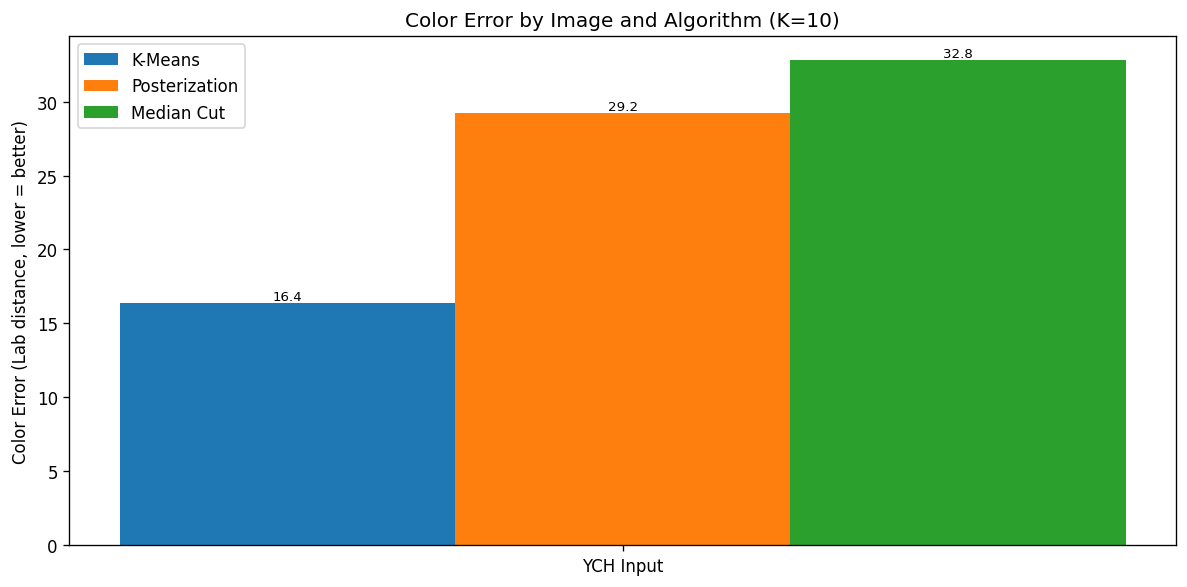

In [8]:
# 02번 입력 이미지에서 알고리즘별 색 오차를 막대그래프로 시각화 (막대가 낮을수록 원본 보존 우수)
image_names = list(COMPARE_IMAGES.keys())
algo_names = list(ALGORITHMS.keys())
x = np.arange(len(image_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
for i, algo in enumerate(algo_names):
    errors = [next(r["color_error"] for r in multi_rows
                   if r["image"] == img and r["algorithm"] == algo)
              for img in image_names]
    bars = ax.bar(x + (i - 1) * width, errors, width, label=algo)
    ax.bar_label(bars, fmt="%.1f", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(image_names)
ax.set_ylabel("Color Error (Lab distance, lower = better)")
ax.set_title(f"Color Error by Image and Algorithm (K={COMPARE_K})")
ax.legend()
plt.tight_layout()
plt.savefig("flowersoutput/01_multi_image_error.png", dpi=160, bbox_inches="tight")
plt.show()

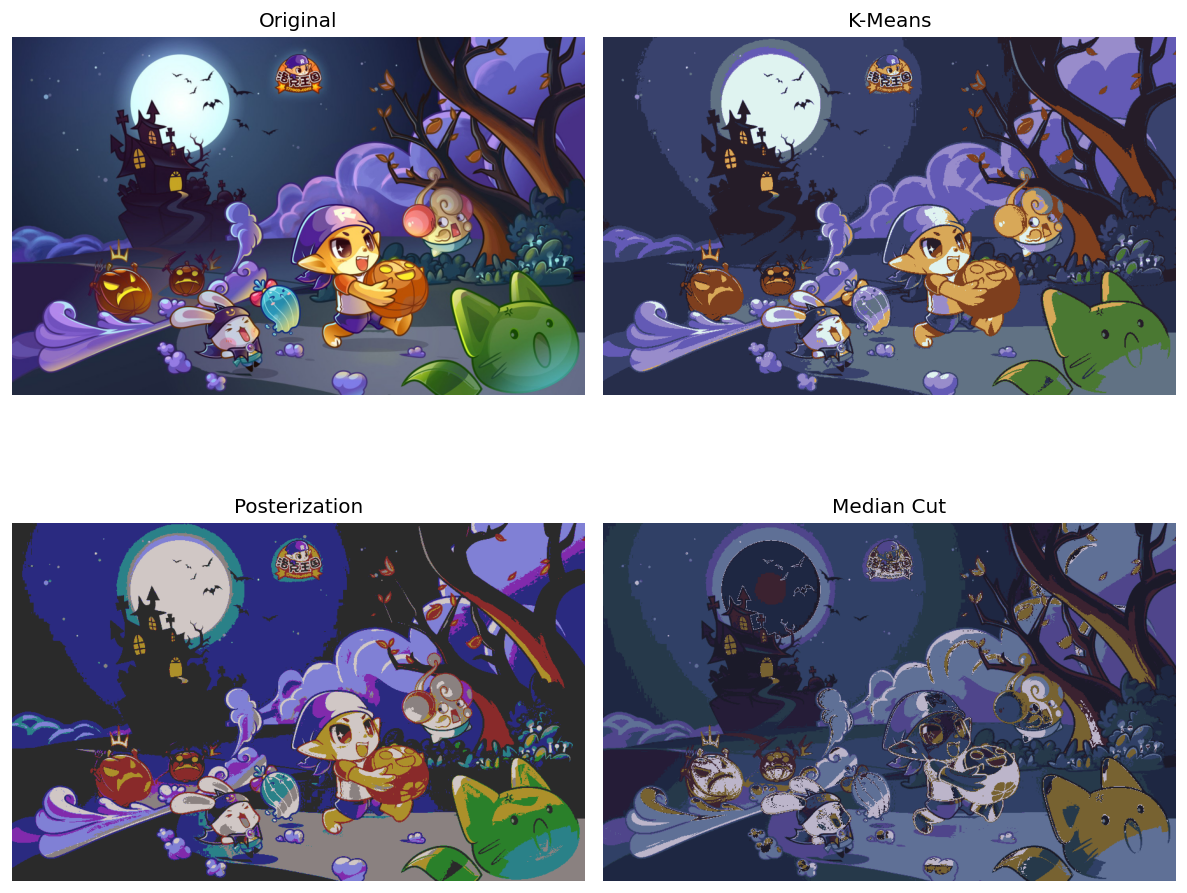

In [9]:
# 02번 입력 이미지 기준 원본 vs 3개 알고리즘 결과를 저장 (발표 슬라이드용)
for img_name in COMPARE_IMAGES:
    items = [
        ("Original", multi_results[(img_name, "Original")]),
        ("K-Means", multi_results[(img_name, "K-Means")]),
        ("Posterization", multi_results[(img_name, "Posterization")]),
        ("Median Cut", multi_results[(img_name, "Median Cut")]),
    ]
    output_name = img_name.lower().replace(" ", "_")
    show_images(items, cols=2, figsize=(10, 9),
                save_path=f"flowersoutput/01_multi_{output_name}.png")